# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with **Gate 1 GO / Gate 2 GO (non-branching) / Gate 3 NA** the manifold
is non-branching, so the branching-only `04_correlation` and `05_modules` notebooks are **not**
produced. This unconditional EMT-TF readout is the final notebook.)*

The EMT-TF panel is scored **data-drivenly** on this dataset: for each candidate factor,
fraction expressing, mean expression in the early (root) vs late (terminus) pseudotime tercile,
and Spearman correlation with pseudotime. We report an early(root) and a late(terminus) factor
among detectably-expressed TFs, and overlay them as a **categorical thresholded-expresser**
map on the grey manifold (house style — not a continuous colormap).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 10368 | pseudotime range 0.0 -> 7.81


### Derive the end-specific EMT-TFs (data-driven)
Panel spans Snail/Zeb/Twist plus mesenchymal FOXC/PRRX families (the Kürten lesson: canonical
Snail/Zeb/Twist alone can miss the root-end factor). Most-negative rho = earliest (root-end);
most-positive = latest (terminus). Only detectably-expressed factors (frac > 3%) are eligible.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0; rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.116       0.069      0.040    -0.037    EARLY(root)
 PRRX1      0.021       0.018      0.006    -0.034    EARLY(root)
TWIST1      0.000       0.000      0.000    -0.008 LATE(terminus)
  ZEB1      0.007       0.003      0.003    -0.008 LATE(terminus)
 SNAI2      0.005       0.002      0.002    -0.007 LATE(terminus)
 SNAI1      0.028       0.008      0.007     0.003    EARLY(root)
TWIST2      0.008       0.003      0.003     0.014 LATE(terminus)
  ZEB2      0.022       0.008      0.008     0.024 LATE(terminus)
 FOXC2      0.004       0.001      0.002     0.027 LATE(terminus)
 PRRX2      0.083       0.024      0.046     0.088 LATE(terminus)

derived pair: FOXC1 (early/root) <-> PRRX2 (late/terminus)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`, **categorical** overlay of
thresholded expressers (upper-quartile-among-expressers) on a grey manifold. Draw order set by
abundance so neither marker is fully occluded.

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.605, 'PRRX2': 0.491} | cells shown: {'FOXC1': 302, 'PRRX2': 215}
FOXC1: 11.6% expressing; 302 shown; mean pseudotime of shown = 0.33 (all = 0.46)
PRRX2: 8.3% expressing; 215 shown; mean pseudotime of shown = 0.56 (all = 0.46)
saved expression.pdf


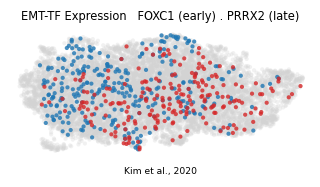

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Kim et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')